In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm


# Figure 4 
## Growth and metabolite plots

Below are <i>Peptonella</i> growth curves and metabolite profiles across a run in the Biospa. Note that genomics/phylogenetic panel were prepared as described in the text (i.e., clinker). Individual panels were edited and merged with the use of adobe illustrator. As with other stacked barplots with overlaid per-replicate data, points are stacked within each replicate (i.e., replicate "A" would have each of its individual metabolite concentrations stacked at the same x-axis jitter location) so the reviewer can parse out variation a bit easier. Bar heights are averages.

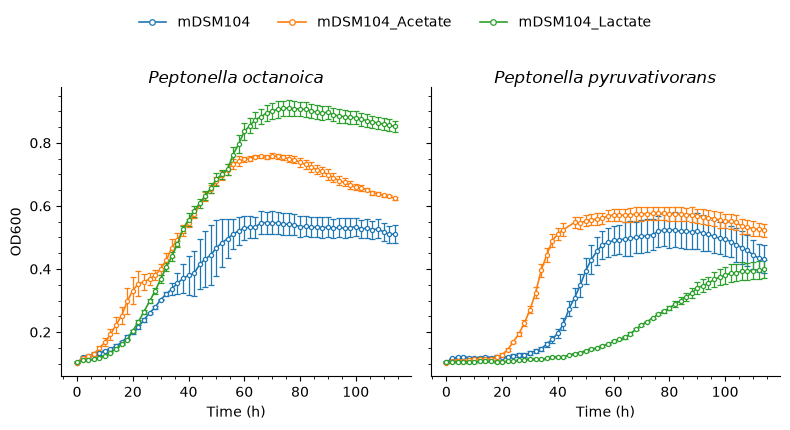

In [4]:
df = pd.read_excel("Figure4.xlsx",sheet_name="OD600")
df = df[~((df["Media"] == "mDSM104_Acetate") & (df["Time (h)"] == 44))] 
# discarded one time point, an OD spike at 44h in both strains 
# -- something to do with biospa/platereader during that reading. 

summary = (
    df.groupby(["Media", "Strain", "Time (h)"], as_index=False)
        .agg(
            Mean=("OD600", "mean"),
            SD=("OD600", "std")
        )
)


strains = summary["Strain"].unique()
media_present = summary["Media"].unique()
colors = dict(zip(media_present, plt.rcParams["axes.prop_cycle"].by_key()["color"]))

markers = {
    "Media1": "o",
    "Media2": "s",
    "Media3": "^",
}

fig, axes = plt.subplots(
    1,
    len(strains),
    figsize=(4 * len(strains), 4),
    sharey=True
)

if len(strains) == 1:
    axes = [axes]

for ax, strain in zip(axes, strains):
    sub = summary[summary["Strain"] == strain]

    for m in media_present:
        sm = (
            sub[sub["Media"] == m]
            .sort_values("Time (h)")
        )

        ax.errorbar(
            sm["Time (h)"],
            sm["Mean"],
            yerr=sm["SD"],
            linestyle="-",
            marker=markers.get(m, "o"),
            color=colors.get(m, "black"),
            ecolor=colors.get(m, "black"),
            linewidth=1.2,
            markersize=3,
            elinewidth=0.9,
            capsize=2,
            capthick=0.9,
            markerfacecolor="white",
            markeredgewidth=0.9,
        )

    ax.set_title(strain, fontstyle="italic", pad=3)
    ax.set_xlabel("Time (h)")

    # Clean axes
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.minorticks_on()

axes[0].set_ylabel("OD600")

# Shared legend
handles = [
    plt.Line2D(
        [0], [0],
        color=colors.get(m, "black"),
        marker=markers.get(m, "o"),
        linestyle="-",
        markersize=4,
        markerfacecolor="white",
        markeredgewidth=0.9,
        linewidth=1.2,
    )
    for m in media_present
]

fig.legend(
    handles,
    media_present,
    loc="upper center",
    ncols=len(media_present),
    frameon=False,
    bbox_to_anchor=(0.5, 1.08),
)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

<i>Peptonella</i> make a diverse array of VFAs on unamended mDSM104 so stacking points over top of the barplots (or displaying error bars) is unfortunately incredibly noisy compared to 104+Lac or 104+Ace.

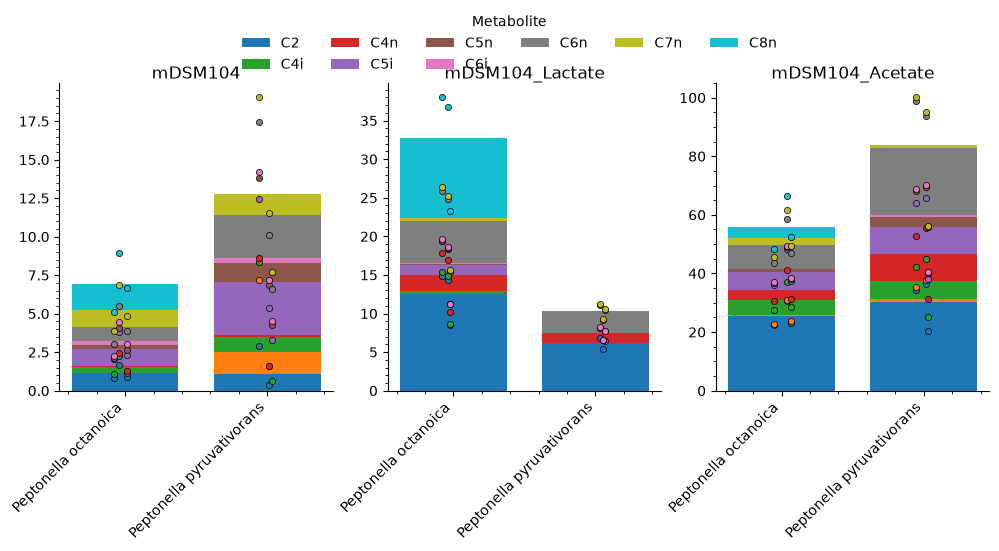

In [ ]:
df = pd.read_excel("Figure4.xlsx",sheet_name="Metabolites")
df["Strain"].unique()
df = df[(df["Strain"]!="Megasphaera hexanoica") & (df["Strain"]!="Blank")]

metabolites = ["C2", "C3", "C4i", "C4n", "C5i", "C5n", "C6i", "C6n", "C7n", "C8n"]

strains = df["Strain"].unique()
media_present = df["Media"].unique()

colors = cm.tab10(np.linspace(0, 1, len(metabolites)+1))

fig, axes = plt.subplots(
    1,
    len(media_present),
    figsize=(4 * len(media_present), 4),
    sharey=False
)

if len(media_present) == 1:
    axes = [axes]

for ax, media in zip(axes, media_present):

    sub = df[df["Media"] == media]

    x_pos = {s: i for i, s in enumerate(strains)}

    for strain in strains:

        ss = sub[sub["Strain"] == strain]
        x = x_pos[strain]

        # Mean stacked bars
        means = ss[metabolites].mean()

        bottom = 0
        for metabolite, color in zip(metabolites, colors):
            val = means[metabolite] if pd.notna(means[metabolite]) else 0
            if val > 0:
                ax.bar(
                    x, val, bottom=bottom, width=bar_width,
                    color=color, edgecolor="none",
                    label=metabolite if (media == media_present[0] and strain == strains[0]) else None,
                )
            bottom += val

        # Replicate stacked points
        for _, row in ss.iterrows():
            jitter = np.random.uniform(-jitter_width, jitter_width)
            bottom = 0

            for metabolite, color in zip(metabolites, colors):
                val = row[metabolite] if pd.notna(row[metabolite]) else 0
                top = bottom + val

                if val > 0:
                    ax.scatter(
                        x + jitter, top,
                        color=color,
                        edgecolor="black",
                        linewidth=0.5,
                        s=20,
                        zorder=3,
                    )

                bottom = top



    ax.set_title(media, pad=3)
    ax.set_xticks(list(x_pos.values()))
    ax.set_xticklabels(list(x_pos.keys()), rotation=45, ha="right")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.minorticks_on()
fig.legend(
    title="Metabolite",
    loc="upper center",
    ncols=6,
    frameon=False,
    bbox_to_anchor=(0.5, 1.08),
)

Given the point made above, plotting endpoint [NH4+] separately makes it much easier to follow the differences in the two species AA utilization across media conditions.

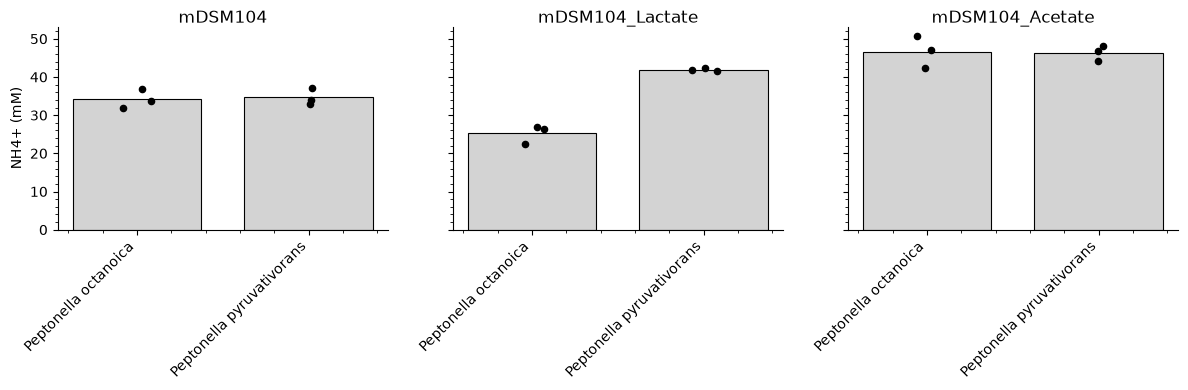

In [ ]:
metabolite = "NH4+"

media_present = df["Media"].unique()
strains = df["Strain"].unique()

fig, axes = plt.subplots(
    1,
    len(media_present),
    figsize=(4 * len(media_present), 4),
    sharey=True
)

if len(media_present) == 1:
    axes = [axes]

bar_width = 0.75
jitter_width = 0.09

for ax, media in zip(axes, media_present):

    sub = df[df["Media"] == media]

    x_pos = {s: i for i, s in enumerate(strains)}

    for strain in strains:

        ss = sub[sub["Strain"] == strain]
        x = x_pos[strain]

        # Mean bar
        mean = ss[metabolite].mean()
        ax.bar(
            x, mean,
            width=bar_width,
            color="lightgray",
            edgecolor="black",
            linewidth=0.8,
        )

        jitter = np.random.uniform(-jitter_width, jitter_width, len(ss))
        ax.scatter(
            x + jitter,
            ss[metabolite],
            color="black",
            s=20,
            zorder=3,
        )

    ax.set_title(media, pad=3)
    ax.set_xticks(list(x_pos.values()))
    ax.set_xticklabels(list(x_pos.keys()), rotation=45, ha="right")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(top=False, right=False)
    ax.minorticks_on()

axes[0].set_ylabel(f"{metabolite} (mM)")

fig.tight_layout()
plt.show()